# Vinculum 02 · Valuation, profitability and balance-sheet ratios

`fundamentals()` returns four valuation ratios ready-made (`vinculum.RATIOS`). Everything else
is a line of polars over the 15 items (see `01_fundamentals.ipynb`). This notebook builds a
ratio library of about twenty ratios and looks at them:

1. built-in ratios
2. a ratio library
3. well-known companies side by side
4. cross-sectional distributions
5. sectors
6. through time: the market's valuation and profitability since 2012
7. one company, daily
8. caveats

All values are point in time: each month-end row uses only filings available that day, and
market cap is that day's.

In [1]:

import matplotlib.pyplot as plt
import polars as pl
from edgar_cortical_node import CONCEPTS, EdgarStore
from subspace_probe import sic_sector, style, timed
from vinculum import RATIOS, Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(60)
v = Vinculum()
edgar = EdgarStore()
ITEMS = [i for i in CONCEPTS if i not in ("eps_basic", "eps_diluted", "public_float")]
with timed("fundamentals, month ends 2012-2026"):
    f = v.fundamentals(ITEMS, start="2012-01-01")
print(f"{f.height:,} rows, {f['cik'].n_unique():,} companies")

fundamentals, month ends 2012-2026: 14.89 s
921,064 rows, 11,116 companies


## 1 · Built-in ratios

Each is a TTM flow or the latest balance sheet over **issuer market cap** (the whole company,
every share class), computed only for USD reporters:

In [2]:
pl.DataFrame({"ratio": list(RATIOS), "numerator": list(RATIOS.values()),
              "meaning": ["inverse P/E", "inverse P/B", "inverse P/S", "inverse P/CF"]})

ratio,numerator,meaning
str,str,str
"""earnings_yield""","""net_income""","""inverse P/E"""
"""book_to_market""","""equity""","""inverse P/B"""
"""sales_to_price""","""revenue""","""inverse P/S"""
"""cash_flow_yield""","""operating_cash_flow""","""inverse P/CF"""


## 2 · A ratio library

The definitions below are plain polars expressions, so they are easy to copy into a study and
change. Rules used throughout:

- A ratio over market cap or enterprise value needs a USD reporter (no FX conversion).
  Within-company ratios (margins, returns, leverage) use one filing's currency and work for
  every company.
- A denominator must be positive: ROE of a company with negative equity, or a margin on zero
  revenue, is missing rather than a misleading sign flip.
- Enterprise value is approximated as market cap + long-term debt − cash (no short-term debt,
  preferred stock or minority interest among the items).
- Missing `dividends_paid` and `capex` stay missing. Zero would be right for a company that
  pays no dividend, but wrong for Pfizer, Amazon or Chevron, which report those numbers under
  tags outside the catalogue (see 01). So dividend yield and free-cash-flow yield cover fewer
  companies than earnings yield does.
- Returns use TTM flows over the latest balance sheet, not an average of two.

In [3]:
mcap, ni, ocf = pl.col("issuer_market_cap"), pl.col("net_income"), pl.col("operating_cash_flow")
rev, assets, equity = pl.col("revenue"), pl.col("assets"), pl.col("equity")
usd = pl.col("currency") == "USD"
capex, divs = pl.col("capex"), pl.col("dividends_paid")
ev = mcap + pl.col("long_term_debt").fill_null(0) - pl.col("cash").fill_null(0)


def ratio(num: pl.Expr, den: pl.Expr, need_usd: bool = False) -> pl.Expr:
    ok = den > 0
    return pl.when((ok & usd) if need_usd else ok).then(num / den)


LIBRARY = {
    # name: (group, formula, expression)
    "earnings_yield": ("valuation", "net income / market cap", pl.col("earnings_yield")),
    "book_to_market": ("valuation", "equity / market cap", pl.col("book_to_market")),
    "sales_to_price": ("valuation", "revenue / market cap", pl.col("sales_to_price")),
    "cash_flow_yield": ("valuation", "operating cash flow / market cap", pl.col("cash_flow_yield")),
    "fcf_yield": ("valuation", "(operating cash flow - capex) / market cap", ratio(ocf - capex, mcap, True)),
    "dividend_yield": ("valuation", "dividends paid / market cap", ratio(divs, mcap, True)),
    "ebit_to_ev": ("valuation", "operating income / EV", ratio(pl.col("operating_income"), ev, True)),
    "sales_to_ev": ("valuation", "revenue / EV", ratio(rev, ev, True)),
    "gross_margin": ("profitability", "gross profit / revenue", ratio(pl.col("gross_profit"), rev)),
    "operating_margin": ("profitability", "operating income / revenue", ratio(pl.col("operating_income"), rev)),
    "net_margin": ("profitability", "net income / revenue", ratio(ni, rev)),
    "roe": ("profitability", "net income / equity", ratio(ni, equity)),
    "roa": ("profitability", "net income / assets", ratio(ni, assets)),
    "gross_profitability": ("profitability", "gross profit / assets (Novy-Marx)", ratio(pl.col("gross_profit"), assets)),
    "cash_roa": ("profitability", "operating cash flow / assets", ratio(ocf, assets)),
    "accruals": ("quality", "(net income - operating cash flow) / assets (Sloan)", ratio(ni - ocf, assets)),
    "asset_turnover": ("quality", "revenue / assets", ratio(rev, assets)),
    "capex_to_sales": ("quality", "capex / revenue", ratio(capex, rev)),
    "payout_ratio": ("quality", "dividends paid / net income", ratio(divs, ni)),
    "debt_to_equity": ("leverage", "long-term debt / equity", ratio(pl.col("long_term_debt"), equity)),
    "liabilities_to_assets": ("leverage", "liabilities / assets", ratio(pl.col("liabilities"), assets)),
    "cash_to_assets": ("leverage", "cash / assets", ratio(pl.col("cash"), assets)),
}
pl.DataFrame([(k, g, txt) for k, (g, txt, _) in LIBRARY.items()], schema=["ratio", "group", "formula"], orient="row")

ratio,group,formula
str,str,str
"""earnings_yield""","""valuation""","""net income / market cap"""
"""book_to_market""","""valuation""","""equity / market cap"""
"""sales_to_price""","""valuation""","""revenue / market cap"""
"""cash_flow_yield""","""valuation""","""operating cash flow / market cap"""
"""fcf_yield""","""valuation""","""(operating cash flow - capex) / market cap"""
"""dividend_yield""","""valuation""","""dividends paid / market cap"""
"""ebit_to_ev""","""valuation""","""operating income / EV"""
"""sales_to_ev""","""valuation""","""revenue / EV"""
"""gross_margin""","""profitability""","""gross profit / revenue"""


In [4]:
with timed("ratios"):
    r = f.with_columns([e.alias(k) for k, (_, _, e) in LIBRARY.items()])
profiles = edgar.profiles(r["cik"].drop_nulls().unique().to_list()).select("cik", "sic", "sic_description")
sectors = {s: sic_sector(s) for s in profiles["sic"].unique().to_list()}
profiles = profiles.with_columns(pl.col("sic").replace_strict(sectors, default=None).alias("sector"))
r = r.join(profiles, on="cik", how="left")
# The panel's largest companies each month (primary class, ranked by issuer market cap).
r = r.with_columns(pl.col("issuer_market_cap").rank("ordinal", descending=True).over("date").alias("size_rank"))
RATIO_NAMES = list(LIBRARY)
print(f"{len(RATIO_NAMES)} ratios on {r.height:,} rows")

ratios: 0.01 s
22 ratios on 921,064 rows


## 3 · Well-known companies side by side

The latest month end. Reading down a column is a quick health check of the data:
- Apple's gross margin is near 49%, Nvidia's operating margin above 60%.
- Coca-Cola pays out most of its earnings.
- JPMorgan has no gross or operating margin: banks have no such lines.
- Gaps follow the items' coverage: no capex for Amazon or Chevron, no dividends for Pfizer
  (tags outside the catalogue), no total liabilities for Walmart or Coca-Cola.

In [5]:
last = r["date"].max()
names = ["AAPL", "MSFT", "NVDA", "AMZN", "TSLA", "JPM", "KO", "WMT", "CVX", "PFE"]
snap = r.filter((pl.col("date") == last) & pl.col("ticker").is_in(names))
table = snap.to_pandas().set_index("ticker").loc[[n for n in names if n in snap["ticker"]], RATIO_NAMES].T
print(f"as known on {last}")
table.round(3)

as known on 2026-10-30


ticker,AAPL,MSFT,NVDA,AMZN,TSLA,JPM,KO,WMT,CVX,PFE
earnings_yield,0.026,0.037,0.039,0.052,0.002,0.073,0.036,0.023,0.044,0.025
book_to_market,0.021,0.121,0.046,0.213,0.056,0.418,0.092,0.100,0.408,0.490
sales_to_price,0.093,0.089,0.061,0.299,0.066,0.223,0.126,0.751,0.463,0.366
cash_flow_yield,0.029,0.051,0.027,0.062,0.012,-0.181,0.040,0.044,0.097,0.077
fcf_yield,0.027,0.015,NaN,NaN,0.002,NaN,0.035,0.014,NaN,0.063
dividend_yield,0.003,0.007,0.001,NaN,NaN,0.019,0.028,0.008,0.030,NaN
ebit_to_ev,0.030,0.042,0.040,0.035,0.002,NaN,0.039,0.032,NaN,NaN
sales_to_ev,0.092,0.089,0.061,0.293,0.066,0.340,0.130,0.732,0.472,0.273
gross_margin,0.487,0.677,0.747,NaN,0.193,NaN,0.623,NaN,NaN,NaN
operating_margin,0.332,0.471,0.652,0.121,0.033,NaN,0.300,0.044,NaN,NaN


## 4 · Cross-sectional distributions

The 1,000 largest companies on the latest month end, each ratio clipped to its 1st-99th
percentile for the plot. Ratios with a small denominator (ROE near zero equity, EV near zero
for cash-rich companies) have long tails; rank or winsorize them before using them as signals.

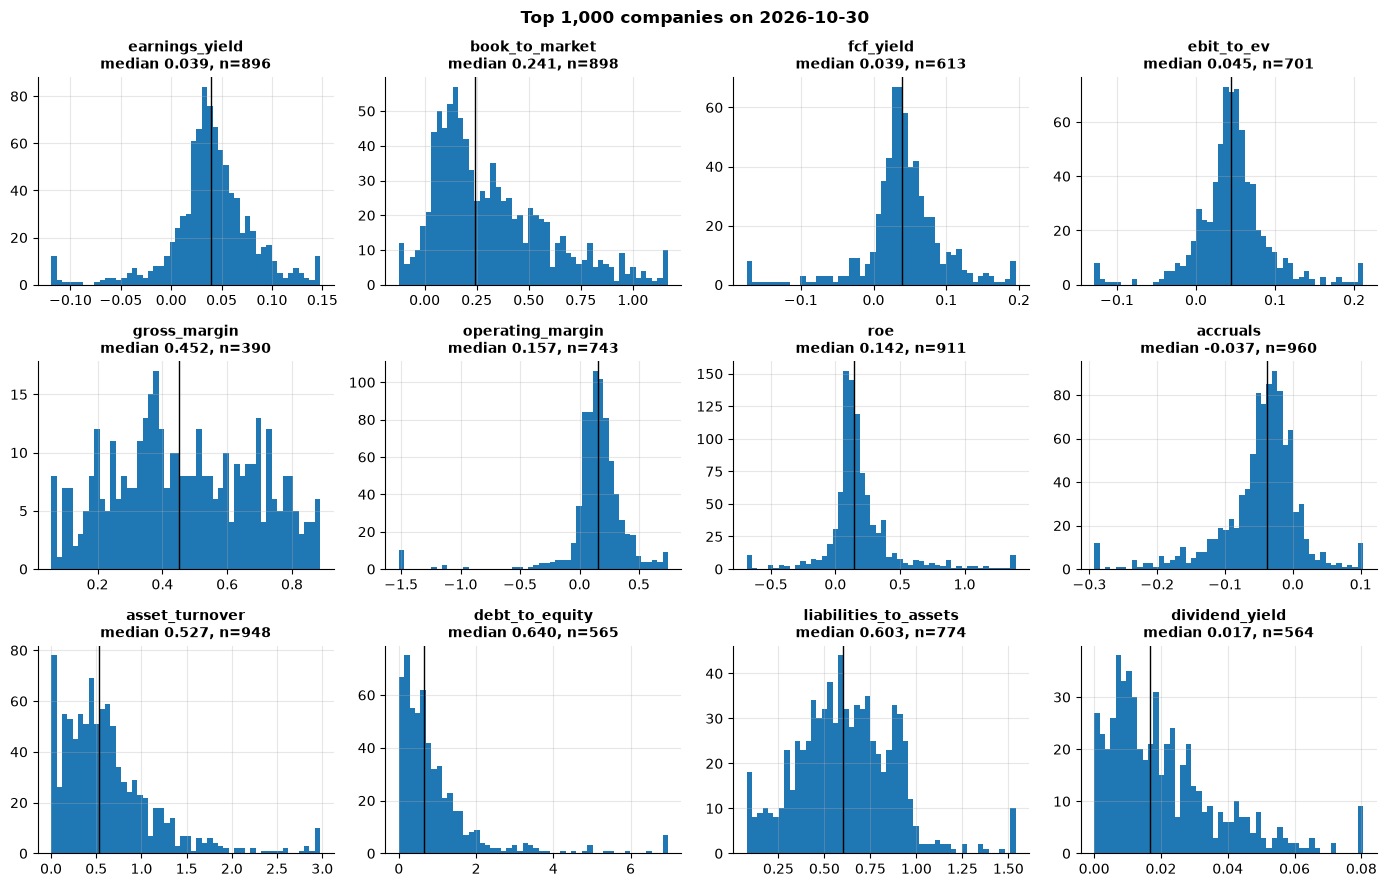

In [6]:
top = r.filter((pl.col("date") == last) & (pl.col("size_rank") <= 1000))
show = ["earnings_yield", "book_to_market", "fcf_yield", "ebit_to_ev",
        "gross_margin", "operating_margin", "roe", "accruals",
        "asset_turnover", "debt_to_equity", "liabilities_to_assets", "dividend_yield"]
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, name in zip(axes.flat, show, strict=True):
    s = top[name].drop_nulls()
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s.clip(lo, hi), bins=50)
    ax.axvline(s.median(), color="black", lw=1)
    ax.set_title(f"{name}\nmedian {s.median():.3f}, n={s.len()}", fontsize=10)
fig.suptitle(f"Top 1,000 companies on {last}", fontweight="bold")
fig.tight_layout()
plt.show()

In [7]:
pl.DataFrame({"ratio": show,
              "coverage": [top[n].is_not_null().mean() for n in show],
              "negative": [(top[n] < 0).mean() for n in show],
              "p01": [top[n].quantile(0.01) for n in show],
              "median": [top[n].median() for n in show],
              "p99": [top[n].quantile(0.99) for n in show]}).with_columns(pl.col(pl.Float64).round(3))

ratio,coverage,negative,p01,median,p99
str,f64,f64,f64,f64,f64
"""earnings_yield""",0.896,0.099,-0.119,0.039,0.148
"""book_to_market""",0.898,0.055,-0.124,0.241,1.168
"""fcf_yield""",0.613,0.111,-0.175,0.039,0.195
"""ebit_to_ev""",0.701,0.097,-0.129,0.045,0.211
"""gross_margin""",0.39,0.0,0.057,0.452,0.887
"""operating_margin""",0.743,0.094,-1.519,0.157,0.743
"""roe""",0.911,0.092,-0.687,0.142,1.394
"""accruals""",0.96,0.88,-0.293,-0.037,0.104
"""asset_turnover""",0.948,0.0,0.001,0.527,2.978


## 5 · Sectors

Sector from the company's SIC code (EDGAR profiles), grouped into the Fama-French 12
industries. SIC is today's code, not point in time, which rarely matters for large companies.
Medians across the top 1,000:

In [8]:
by_sector = (top.filter(pl.col("sector").is_not_null()).group_by("sector")
             .agg(pl.len().alias("companies"), pl.col("gross_margin").is_not_null().mean().alias("has_gross_margin"),
                  *[pl.col(c).median() for c in ["gross_margin", "operating_margin", "roe", "earnings_yield",
                                                 "book_to_market", "dividend_yield", "debt_to_equity",
                                                 "liabilities_to_assets", "asset_turnover"]])
             .sort("companies", descending=True).with_columns(pl.col(pl.Float64).round(3)))
by_sector

sector,companies,has_gross_margin,gross_margin,operating_margin,roe,earnings_yield,book_to_market,dividend_yield,debt_to_equity,liabilities_to_assets,asset_turnover
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Finance""",203,0.069,0.61,0.209,0.119,0.058,0.498,0.024,0.653,0.808,0.141
"""Business equipment""",185,0.714,0.638,0.157,0.156,0.025,0.133,0.007,0.483,0.47,0.564
"""Other""",145,0.255,0.382,0.173,0.181,0.039,0.197,0.01,0.804,0.627,0.591
"""Manufacturing""",104,0.625,0.362,0.153,0.158,0.035,0.218,0.011,0.531,0.566,0.684
"""Healthcare""",96,0.344,0.644,0.133,0.112,0.025,0.155,0.008,0.663,0.506,0.558
"""Shops""",72,0.625,0.313,0.085,0.246,0.045,0.148,0.018,0.698,0.702,1.454
"""Utilities""",56,0.0,null,0.239,0.103,0.047,0.448,0.029,1.448,0.733,0.2
"""Energy""",39,0.077,0.349,0.158,0.123,0.065,0.551,0.021,0.282,0.474,0.493
"""Consumer non-durables""",34,0.853,0.494,0.157,0.173,0.045,0.354,0.031,0.525,0.645,0.649


The familiar patterns show up:
- **Finance** has the most liabilities per unit of assets (banks fund themselves with
  deposits) and the slowest asset turnover. Only 7% of financial companies report a gross
  margin, so that median describes a few exchanges and payment companies, not banks.
- **Business equipment** (technology) and **Healthcare** have the highest gross margins and
  the lowest book-to-market.
- **Energy** is the cheapest sector on earnings yield and book-to-market.
- **Utilities** carry the most debt per unit of equity and, with consumer staples, pay the
  highest dividends. No utility reports a gross profit line.
- **Shops** (retail and wholesale) turn their assets over fastest, on thin operating margins.

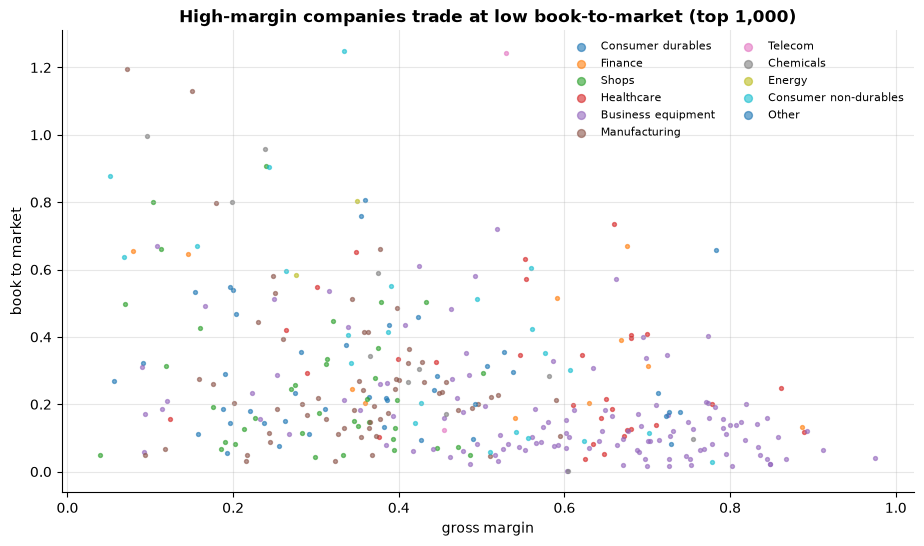

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
pts = top.filter(pl.col("sector").is_not_null() & pl.col("gross_margin").is_between(-0.5, 1)
                 & pl.col("book_to_market").is_between(0, 3))
for name, g in pts.group_by("sector"):
    ax.scatter(g["gross_margin"], g["book_to_market"], s=8, alpha=0.6, label=name[0])
ax.set_xlabel("gross margin")
ax.set_ylabel("book to market")
ax.set_title("High-margin companies trade at low book-to-market (top 1,000)")
ax.legend(fontsize=8, ncol=2, markerscale=2)
plt.show()

## 6 · Through time

Medians across the 500 largest companies each month end (ranked by issuer market cap within
the panel), and the aggregate P/E (total market cap / total TTM net income of the same 500,
USD reporters), which is what an index P/E measures.

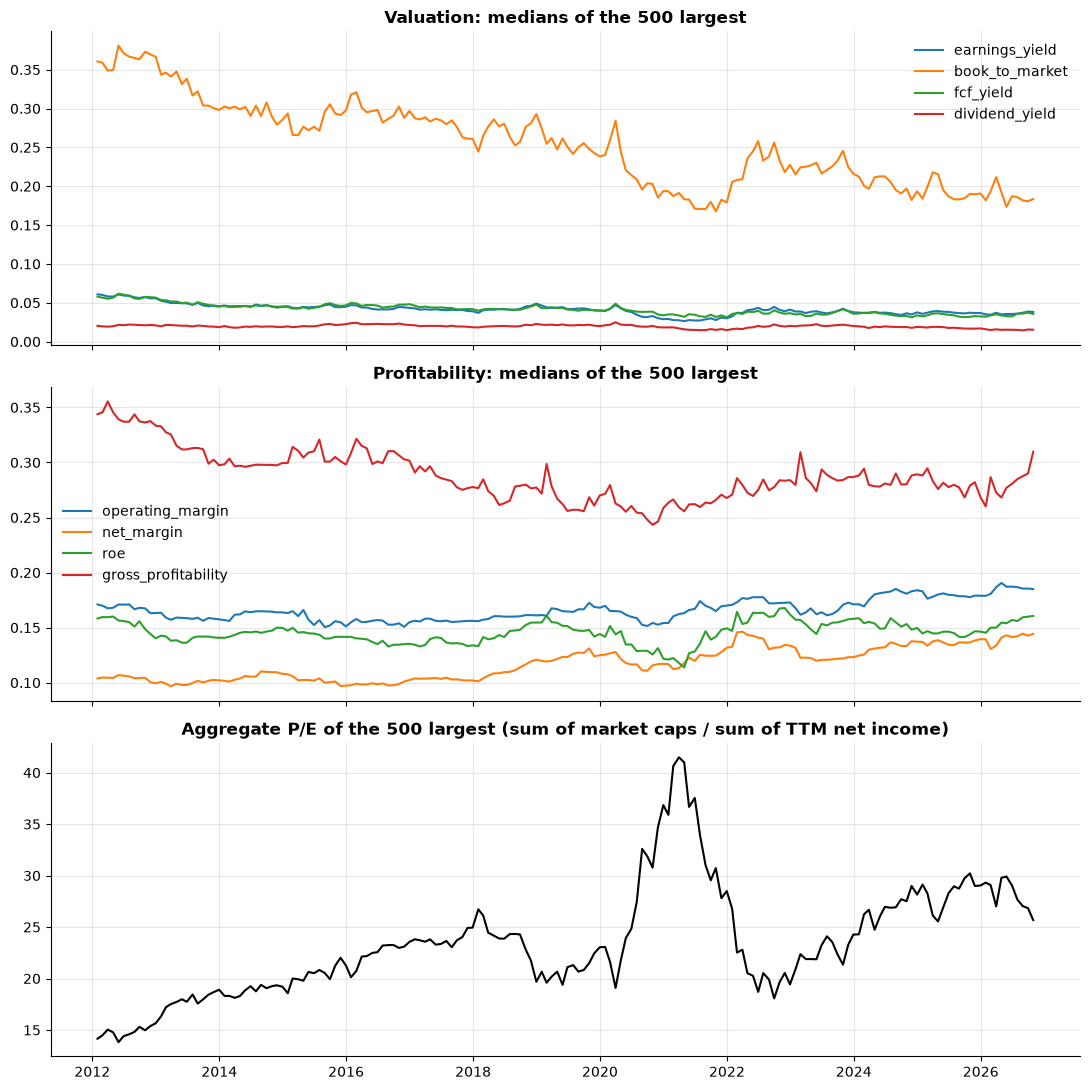

In [10]:
big = r.filter(pl.col("size_rank") <= 500)
med = big.group_by("date").agg(
    *[pl.col(c).median() for c in ["earnings_yield", "book_to_market", "fcf_yield", "dividend_yield",
                                   "operating_margin", "net_margin", "roe", "gross_profitability"]],
    (pl.col("issuer_market_cap").filter(usd & ni.is_not_null()).sum()
     / ni.filter(usd).sum()).alias("aggregate_pe")).sort("date")
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for c in ["earnings_yield", "book_to_market", "fcf_yield", "dividend_yield"]:
    axes[0].plot(med["date"], med[c], label=c)
axes[0].set_title("Valuation: medians of the 500 largest")
axes[0].legend()
for c in ["operating_margin", "net_margin", "roe", "gross_profitability"]:
    axes[1].plot(med["date"], med[c], label=c)
axes[1].set_title("Profitability: medians of the 500 largest")
axes[1].legend()
axes[2].plot(med["date"], med["aggregate_pe"], color="black")
axes[2].set_title("Aggregate P/E of the 500 largest (sum of market caps / sum of TTM net income)")
fig.tight_layout()
plt.show()

In [11]:
med.filter(pl.col("date").dt.month() == 12).select(
    pl.col("date").dt.year().alias("year"), pl.col("aggregate_pe").round(1),
    (1 / pl.col("earnings_yield")).round(1).alias("median_pe"), pl.col("dividend_yield").round(4),
    pl.col("operating_margin").round(3))

year,aggregate_pe,median_pe,dividend_yield,operating_margin
i32,f64,f64,f64,f64
2012,15.7,17.9,0.021,0.163
2013,18.9,21.9,0.0185,0.158
2014,19.2,22.2,0.0189,0.164
2015,21.3,22.3,0.0225,0.151
2016,23.6,23.0,0.0214,0.155
2017,24.9,25.6,0.0185,0.156
2018,19.7,20.4,0.0228,0.161
2019,23.0,25.0,0.0199,0.168
2020,36.8,34.7,0.0183,0.154


The aggregate P/E tracks the published S&P 500 trailing P/E:
- mid-teens in 2012;
- high 30s at the end of 2020, when pandemic earnings collapsed;
- back below 20 after the 2022 sell-off;
- near 29 in 2025.

Operating margins of the largest companies rose from about 16% to 18%. The median dividend
yield is over companies reporting dividends, so it reads higher than an index yield.

## 7 · One company, daily

With `freq="1d"` every trading day gets a row: the price moves the ratio daily, and each filing
moves it in a step. Apple's P/E (1 / earnings yield) and the TTM net income behind it:

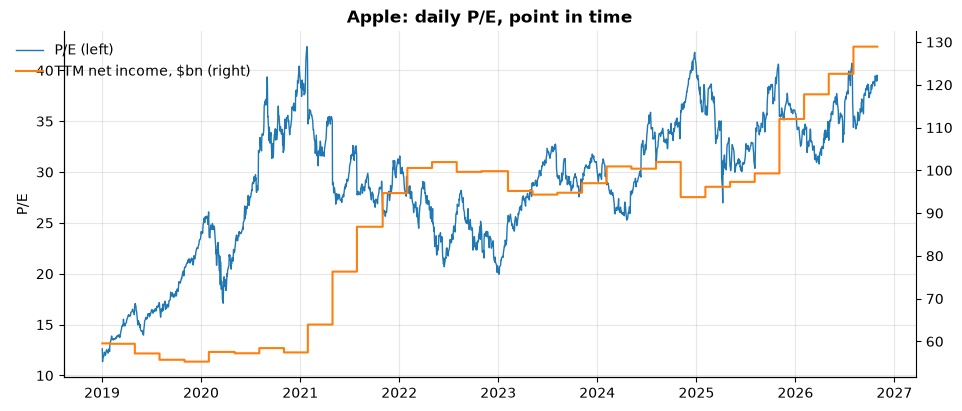

In [12]:
a = v.fundamentals(["net_income", "equity"], start="2019-01-01", tickers="AAPL", freq="1d")
fig, ax = plt.subplots()
ax.plot(a["date"], 1 / a["earnings_yield"], lw=1, label="P/E (left)")
ax.set_ylabel("P/E")
ax2 = ax.twinx()
ax2.step(a["date"], a["net_income"] / 1e9, where="post", color="tab:orange", label="TTM net income, $bn (right)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Apple: daily P/E, point in time")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.show()

## 8 · Caveats

- **Banks, insurers, REITs.** Revenue means different things (see 01), there is no gross profit
  or operating income for banks, and debt ratios are not comparable with industrial companies.
  Compare within a sector, or exclude Finance for margin and EV ratios.
- **Enterprise value is approximate**: no short-term debt, leases, preferred or minority
  interest; companies without a `long_term_debt` tag count as debt-free.
- **USD reporters only** for anything over market cap; foreign filers' within-company ratios
  are fine, apart from the known issue with convenience translations described in 01.
- **Multi-class companies** are valued through their primary class: `issuer_market_cap`
  covers all classes, so ratios are company-wide. Companies without a company-wide share count
  (Berkshire after 2016) have no market cap and so no valuation ratios.
- **Point in time but not survivorship-filtered here**: the 500/1,000 largest are chosen each
  month from what existed then, so delisted companies are included while they traded.
- **Sector is today's SIC**, and the 12-industry grouping is coarse.